<a href="https://colab.research.google.com/github/Geralf21/Analisis_Patrocinios_Clubes_Brasileros/blob/main/%20notebooks/TP_pregunta4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#¿El nivel de ingresos comerciales por sponsoreo difiere significativamente entre los equipos que clasifican a la Copa Libertadores frente a los que van a la Copa Sudamericana o no juegan torneos internacionales?

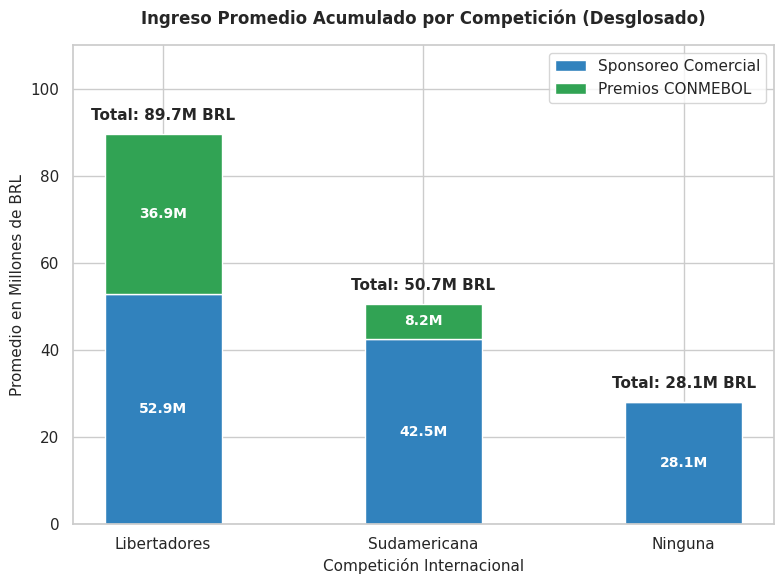

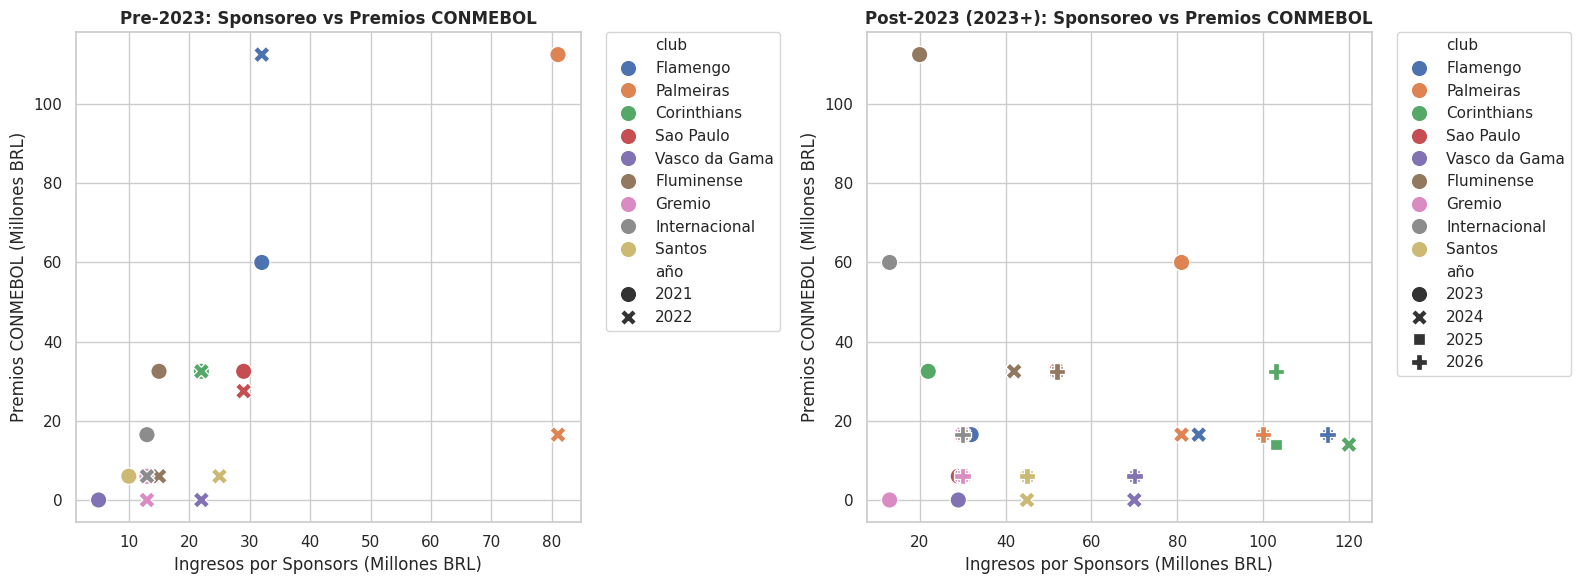

In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#aca tuve que actualizar la ruta del archivo porque no me lo corria
df = pd.read_csv('/content/sample_data/brasileirao_futbolistico.csv')

def calcular_premios_conmebol(row):
    comp = row['competicion_internacional']
    club = row['club']
    año = row['año']

    if comp == 'Ninguna':
        return 0.0
    elif comp == 'Sudamericana':
        if (club == 'Red Bull Bragantino' and año == 2021) or (club == 'Sao Paulo' and año == 2022) or (club == 'Fortaleza' and año == 2023):
            return 5.5
        elif club in ['Athletico-PR', 'Corinthians', 'Atlético Goianiense', 'Ceará', 'America-MG']:
            return 2.8
        else:
            return 1.2
    elif comp == 'Libertadores':
        if (club == 'Palmeiras' and año == 2021) or (club == 'Flamengo' and año == 2022) or (club == 'Fluminense' and año == 2023):
            return 22.5
        elif (club == 'Flamengo' and año == 2021) or (club == 'Athletico-PR' and año == 2022) or (club in ['Palmeiras', 'Internacional'] and año == 2023):
            return 12.0
        elif club in ['Atlético Mineiro', 'Sao Paulo', 'Corinthians', 'Fluminense']:
            return 6.5
        else:
            return 3.3

df['premios_conmebol_millones_USD'] = df.apply(calcular_premios_conmebol, axis=1)
df['premios_conmebol_millones_BRL'] = df['premios_conmebol_millones_USD'] * 5.0
df['ingreso_total_internacional_BRL'] = df['ingresos_sponsors_millones_BRL'] + df['premios_conmebol_millones_BRL']

# aca filtro los dataframes por periodo
df_periodo1 = df[df['año'] < 2023].copy()
df_periodo2 = df[df['año'] >= 2023].copy()

#aca hago el grafico de barras
resumen_barras = df.groupby('competicion_internacional').agg(
    sponsoreo_mean=('ingresos_sponsors_millones_BRL', 'mean'),
    premios_mean=('premios_conmebol_millones_BRL', 'mean'),
    total_mean=('ingreso_total_internacional_BRL', 'mean')
).reindex(['Libertadores', 'Sudamericana', 'Ninguna']).reset_index()

fig1, ax1 = plt.subplots(figsize=(8, 6))
sns.set_theme(style="whitegrid")

ax1.bar(resumen_barras['competicion_internacional'], resumen_barras['sponsoreo_mean'], label='Sponsoreo Comercial', color='#3182bd', width=0.45)
ax1.bar(resumen_barras['competicion_internacional'], resumen_barras['premios_mean'], bottom=resumen_barras['sponsoreo_mean'], label='Premios CONMEBOL', color='#31a354', width=0.45)

for i, row in resumen_barras.iterrows():
    sp = row['sponsoreo_mean']
    pr = row['premios_mean']
    tot = row['total_mean']

    ax1.text(i, sp / 2, f"{sp:.1f}M", ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    if pr > 0:
        ax1.text(i, sp + (pr / 2), f"{pr:.1f}M", ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    ax1.text(i, tot + 2.5, f"Total: {tot:.1f}M BRL", ha='center', va='bottom', fontweight='bold', fontsize=11)

ax1.set_title("Ingreso Promedio Acumulado por Competición (Desglosado)", fontsize=12, fontweight='bold', pad=15)
ax1.set_ylabel("Promedio en Millones de BRL", fontsize=11)
ax1.set_xlabel("Competición Internacional", fontsize=11)
ax1.set_ylim(0, 110)
ax1.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# aca genero el scatterplots
fig2, (ax1_sc, ax2_sc) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot Pre-2023
sns.scatterplot(
    data=df_periodo1,
    x="ingresos_sponsors_millones_BRL",
    y="premios_conmebol_millones_BRL",
    hue="club",
    style="año",
    s=140,
    ax=ax1_sc
    )
ax1_sc.set_title("Pre-2023: Sponsoreo vs Premios CONMEBOL", fontsize=12, fontweight='bold')
ax1_sc.set_xlabel("Ingresos por Sponsors (Millones BRL)")
ax1_sc.set_ylabel("Premios CONMEBOL (Millones BRL)")
ax1_sc.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

# Subplot Post-2023
sns.scatterplot(
    data=df_periodo2,
    x="ingresos_sponsors_millones_BRL",
    y="premios_conmebol_millones_BRL",
    hue="club",
    style="año",
    s=140,
    ax=ax2_sc
)
ax2_sc.set_title("Post-2023 (2023+): Sponsoreo vs Premios CONMEBOL", fontsize=12, fontweight='bold')
ax2_sc.set_xlabel("Ingresos por Sponsors (Millones BRL)")
ax2_sc.set_ylabel("Premios CONMEBOL (Millones BRL)")
ax2_sc.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()